# 03 Item Response Theory for a Patient-Reported Outcome

**Setting:** a patient-reported fatigue item bank (healthcare).
**Methods:** graded response model and 2PL, both fit by marginal maximum
likelihood (Bock-Aitkin EM, written from scratch); EAP scoring; item and
test information; DIF detection with Mantel-Haenszel (with
purification) and logistic regression.
**Ground truth:** item parameters are drawn and fixed before simulation,
and DIF is planted on four known items.

Classical test theory gives one reliability for the whole scale. IRT
describes each item: how sharply it separates people (discrimination,
a) and where on the trait it does so (thresholds, b). That item-level
view is what makes short forms, adaptive tests, and fairness checks
possible.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_root = pathlib.Path.cwd()
if _root.name == "notebooks":
    _root = _root.parent
sys.path.insert(0, str(_root / "src"))
FIG_DIR = _root / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
# Categorical slots (validated palette), plus ink for the known truth
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED = "#0b0b0b", "#8a8984"

In [2]:
from surveyhub.simulate import bank_grm, bank_2pl, simulate_irt, simulate_dif
from surveyhub.irt import (fit_grm, fit_2pl, category_probs, item_information,
                           mantel_haenszel, logistic_dif)

## 1. A 10-item short form with five response options

"In the past 7 days, how often did you feel tired?" Never, Rarely,
Sometimes, Often, Always. Samejima's graded response model:

P(X >= k | theta) = logistic(a (theta - b_k)),   k = 1..4

Simulate 2,000 patients and fit the model.

In [3]:
grm_true = bank_grm(10, 5, seed=31)
grm_data = simulate_irt(grm_true, 2000, seed=32)
grm = fit_grm(grm_data.X)
print(f"EM converged: {grm.converged} after {grm.n_iter} iterations")
print(f"discrimination: r = {np.corrcoef(grm.a, grm_true.a)[0, 1]:.3f}, "
      f"RMSE = {np.sqrt(np.mean((grm.a - grm_true.a) ** 2)):.3f}")
print(f"thresholds:     r = {np.corrcoef(grm.b.ravel(), grm_true.b.ravel())[0, 1]:.4f}, "
      f"RMSE = {np.sqrt(np.mean((grm.b - grm_true.b) ** 2)):.3f}\n")
print(f"{'item':<5s} {'a true':>7s} {'a est':>7s}   thresholds true -> est")
for j in range(10):
    tb = " ".join(f"{v:5.2f}" for v in grm_true.b[j])
    eb = " ".join(f"{v:5.2f}" for v in grm.b[j])
    print(f"{j + 1:<5d} {grm_true.a[j]:7.2f} {grm.a[j]:7.2f}   {tb}  ->  {eb}")

EM converged: True after 29 iterations
discrimination: r = 0.990, RMSE = 0.073
thresholds:     r = 0.9987, RMSE = 0.055

item   a true   a est   thresholds true -> est
1        2.35    2.34   -1.74 -0.55  0.48  1.20  ->  -1.77 -0.61  0.48  1.19
2        1.10    1.06   -0.44  0.33  1.12  1.73  ->  -0.42  0.42  1.23  1.86
3        2.01    1.95   -1.09 -0.18  0.80  1.76  ->  -1.05 -0.16  0.84  1.78
4        1.71    1.85   -0.93  0.02  0.71  1.72  ->  -0.87  0.05  0.74  1.77
5        2.02    1.92   -1.41 -0.41  0.39  1.01  ->  -1.48 -0.44  0.38  1.02
6        1.06    1.03   -1.31 -0.27  0.73  1.69  ->  -1.35 -0.29  0.77  1.70
7        1.08    1.18   -0.30  0.53  1.38  2.01  ->  -0.31  0.44  1.26  1.91
8        1.26    1.34   -1.88 -0.70  0.38  1.11  ->  -1.84 -0.74  0.31  1.02
9        2.47    2.46   -0.74  0.23  0.85  1.70  ->  -0.72  0.20  0.82  1.66
10       1.45    1.40   -0.68  0.30  1.16  2.13  ->  -0.71  0.34  1.16  2.17


In [4]:
theta_hat, post_sd = grm.eap(grm_data.X)
print(f"EAP scores vs true trait: r = {np.corrcoef(theta_hat, grm_data.theta)[0, 1]:.3f}")
print(f"actual RMSE {np.sqrt(np.mean((theta_hat - grm_data.theta) ** 2)):.3f} "
      f"vs average posterior SD {np.sqrt(np.mean(post_sd ** 2)):.3f} (calibrated uncertainty)")

grid = np.linspace(-4, 4, 161)
info = grm.test_info(grid)
for t in (-2, -1, 0, 1, 2):
    q = np.argmin(np.abs(grid - t))
    print(f"theta = {t:+d}: test information {info[q]:5.2f}, SE {1 / np.sqrt(info[q]):.2f}")

EAP scores vs true trait: r = 0.943
actual RMSE 0.336 vs average posterior SD 0.337 (calibrated uncertainty)
theta = -2: test information  4.33, SE 0.48
theta = -1: test information  7.83, SE 0.36
theta = +0: test information  8.84, SE 0.34
theta = +1: test information  8.88, SE 0.34
theta = +2: test information  6.01, SE 0.41


Precision varies along the trait: the short form measures moderate
fatigue well and the extremes less well. A single reliability
coefficient hides this.

## 2. A 40-item symptom checklist and differential item functioning

Yes/no items, 2PL model. Patients under 65 (reference) and 65 and over
(focal); the older group truly has more fatigue (impact, which is fine).
On four items, older patients at the same fatigue level answer
differently: for example "I had to limit my social activity" may be
endorsed more by older patients for reasons unrelated to fatigue. That
is DIF, and it biases group comparisons.

In [5]:
bank40 = bank_2pl(40, a_range=(1.0, 2.2), seed=33)
planted = [4, 13, 21, 33]
dif_data = simulate_dif(bank40, 1500, 1500, planted, [0.6, -0.7, 0.6, -0.8],
                        focal_mean=0.4, seed=34)
m2pl = fit_2pl(dif_data.X)
print(f"2PL on the pooled sample: a r = {np.corrcoef(m2pl.a, bank40.a)[0, 1]:.3f}, "
      f"b r = {np.corrcoef(m2pl.b[:, 0], bank40.b[:, 0])[0, 1]:.4f}")

raw_gap = dif_data.X[dif_data.group == 1].mean() - dif_data.X[dif_data.group == 0].mean()
print(f"older patients endorse {raw_gap * 40:+.1f} more of the 40 items on average "
      f"(true impact: +0.4 SD more fatigue)")

2PL on the pooled sample: a r = 0.972, b r = 0.9939
older patients endorse +3.1 more of the 40 items on average (true impact: +0.4 SD more fatigue)


In [6]:
mh = mantel_haenszel(dif_data.X, dif_data.group, purify=True)
lr = logistic_dif(dif_data.X, dif_data.group)
print("Mantel-Haenszel flags (with purification):", [int(j) for j in np.flatnonzero(mh.flagged)])
print("logistic-regression flags (Bonferroni):    ", [int(j) for j in np.flatnonzero(lr.p_total * 40 < 0.05)])
print("planted DIF items:                         ", planted, "\n")
print(f"{'item':<5s} {'b shift':>8s} {'MH delta':>9s} {'ETS':>4s} {'LR chi2':>8s}")
for j in sorted(set(planted) | set(np.flatnonzero(mh.flagged))):
    print(f"{j:<5d} {dif_data.dif_shift[j]:+8.2f} {mh.delta[j]:+9.2f} {mh.ets_class[j]:>4s} {lr.total_chi2[j]:8.1f}")
print(f"\nlargest |delta| among the 36 clean items: {np.abs(np.delete(mh.delta, planted)).max():.2f}")

Mantel-Haenszel flags (with purification): [4, 13, 21, 33]
logistic-regression flags (Bonferroni):     [4, 13, 21, 33]
planted DIF items:                          [4, 13, 21, 33] 

item   b shift  MH delta  ETS  LR chi2
4        +0.60     -2.50    C    142.9
13       -0.70     +2.48    C    140.2
21       +0.60     -1.35    B     51.7
33       -0.80     +2.19    C    115.2

largest |delta| among the 36 clean items: 0.49


ETS classes: A (negligible), B (moderate), C (large, |delta| >= 1.5).
Negative delta means the item is harder to endorse for the focal group
at the same trait level.

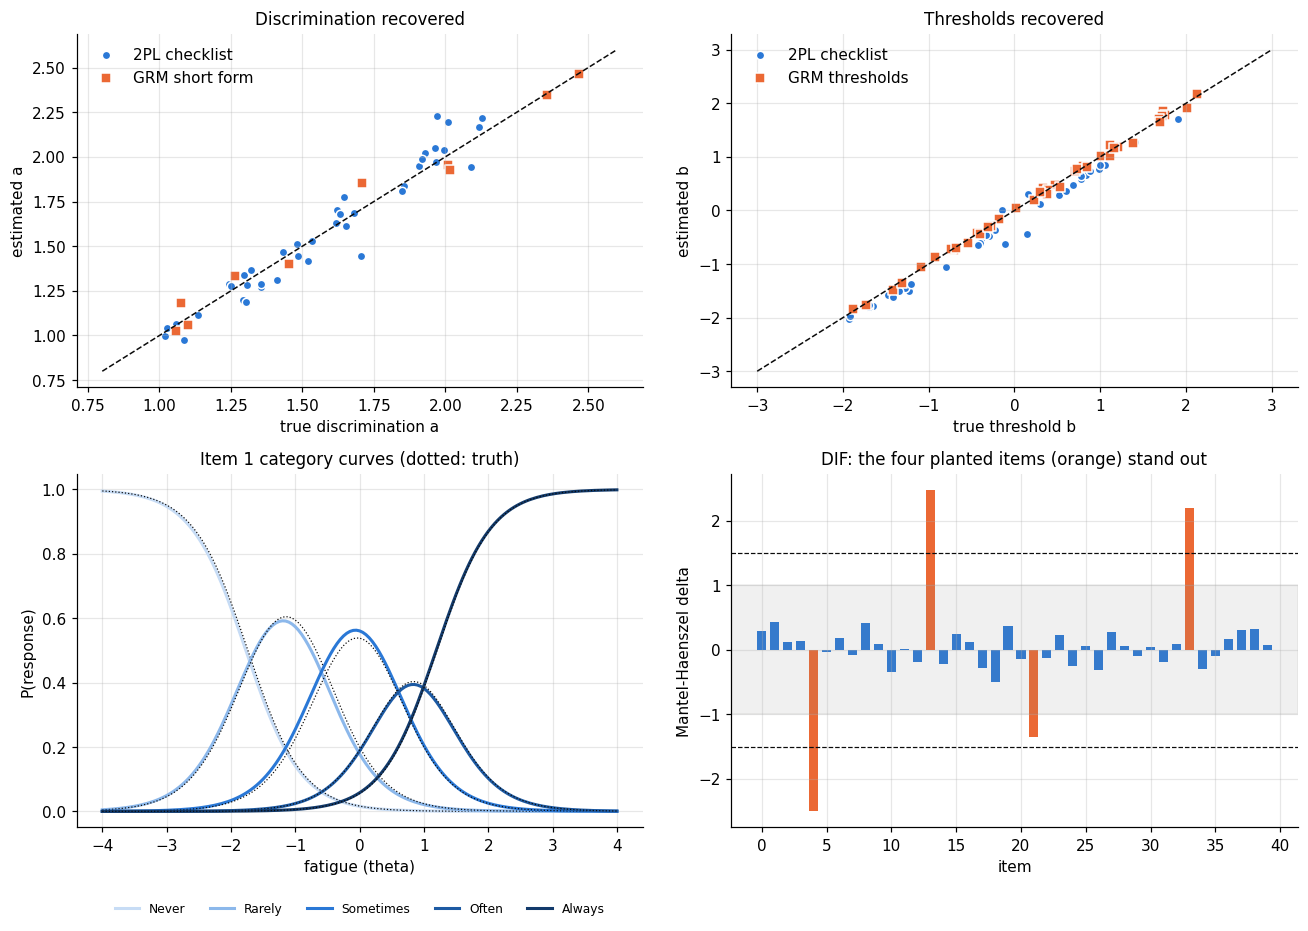

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
ax = axes[0, 0]
ax.scatter(bank40.a, m2pl.a, s=30, color=BLUE, edgecolor="white", linewidth=1, label="2PL checklist")
ax.scatter(grm_true.a, grm.a, s=40, marker="s", color=ORANGE, edgecolor="white", linewidth=1, label="GRM short form")
lims = [0.8, 2.6]
ax.plot(lims, lims, color=INK, lw=1, ls="--")
ax.set_xlabel("true discrimination a")
ax.set_ylabel("estimated a")
ax.set_title("Discrimination recovered", fontsize=11)
ax.legend(frameon=False)

ax = axes[0, 1]
ax.scatter(bank40.b[:, 0], m2pl.b[:, 0], s=30, color=BLUE, edgecolor="white", linewidth=1, label="2PL checklist")
ax.scatter(grm_true.b.ravel(), grm.b.ravel(), s=40, marker="s", color=ORANGE, edgecolor="white", linewidth=1, label="GRM thresholds")
lims = [-3, 3]
ax.plot(lims, lims, color=INK, lw=1, ls="--")
ax.set_xlabel("true threshold b")
ax.set_ylabel("estimated b")
ax.set_title("Thresholds recovered", fontsize=11)
ax.legend(frameon=False)

ax = axes[1, 0]
P = category_probs(grm.a[:1], grm.d[:1], grid)[0]
Pt = category_probs(grm_true.a[:1], grm_true.d[:1], grid)[0]
cat_names = ["Never", "Rarely", "Sometimes", "Often", "Always"]
shades = ["#c7dcf5", "#8cb8eb", "#2a78d6", "#1d5aa3", "#123a6b"]
for k in range(5):
    ax.plot(grid, P[:, k], color=shades[k], lw=2, label=cat_names[k])
    ax.plot(grid, Pt[:, k], color=INK, lw=0.8, ls=":")
ax.set_xlabel("fatigue (theta)")
ax.set_ylabel("P(response)")
ax.set_title("Item 1 category curves (dotted: truth)", fontsize=11)
ax.legend(frameon=False, fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.18))

ax = axes[1, 1]
cols = [ORANGE if j in planted else BLUE for j in range(40)]
ax.bar(np.arange(40), mh.delta, color=cols, width=0.7)
for v in (-1.5, 1.5):
    ax.axhline(v, color=INK, lw=0.8, ls="--")
ax.axhspan(-1, 1, color=MUTED, alpha=0.12)
ax.set_xlabel("item")
ax.set_ylabel("Mantel-Haenszel delta")
ax.set_title("DIF: the four planted items (orange) stand out", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "irt_recovery_dif.png", dpi=150, bbox_inches="tight")
plt.show()

## Takeaways

* The EM implementation recovers discriminations and thresholds for both
  the polytomous short form and the dichotomous checklist, and its EAP
  posterior SDs match the actual scoring error.
* Test information shows where on the trait a scale is precise, which
  is the basis for choosing short-form items and for adaptive testing
  (notebook 04).
* DIF methods separate a real group difference (impact) from items that
  behave differently across groups. Mantel-Haenszel with purification
  flags exactly the four planted items and none of the 36 clean ones.